In [ ]:
import pandas as pd

# 예시 데이터 (공부시간 vs 시험점수)
data = {
    "study_time": [2, 3, 4, 5, 6, 7, 8],
    "exam_score": [50, 55, 60, 65, 70, 78, 85]
}
df = pd.DataFrame(data)

# Pearson 상관계수
print(df.corr(method="pearson"))


            study_time  exam_score
study_time    1.000000    0.995117
exam_score    0.995117    1.000000


In [ ]:
# Spearman Rank 상관계수
print(df.corr(method="spearman"))

            study_time  exam_score
study_time         1.0         1.0
exam_score         1.0         1.0


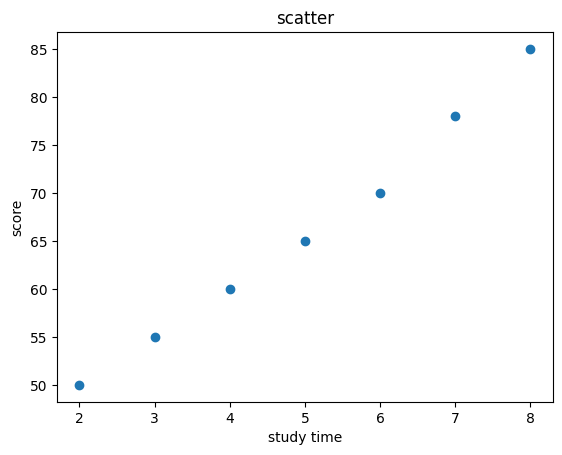

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(df["study_time"], df["exam_score"])
plt.xlabel("study time")
plt.ylabel("score")
plt.title("scatter")
plt.show()

In [ ]:
import statsmodels.api as sm

X = df["study_time"]
y = df["exam_score"]

X = sm.add_constant(X)  # 절편 추가
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             exam_score   R-squared:                       0.990
Model:                            OLS   Adj. R-squared:                  0.988
Method:                 Least Squares   F-statistic:                     508.3
Date:                Mon, 08 Sep 2025   Prob (F-statistic):           3.19e-06
Time:                        11:07:19   Log-Likelihood:                -10.854
No. Observations:                   7   AIC:                             25.71
Df Residuals:                       5   BIC:                             25.60
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         37.3929      1.373     27.225      0.0

/usr/local/lib/python3.12/dist-packages/statsmodels/stats/stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 7 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


공부시간 6시간일 때 예상 점수: 106.50점


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44277 (\N{HANGUL SYLLABLE GONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48512 (\N{HANGUL SYLLABLE BU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54744 (\N{HANGUL SYLLABLE HEOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/

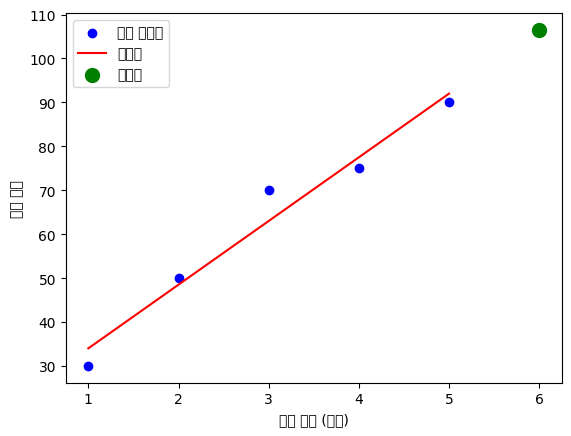

In [1]:
# 간단한 선형회귀 예제
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 데이터 (공부시간, 시험 점수)
X = np.array([[1], [2], [3], [4], [5]])   # 공부 시간
y = np.array([30, 50, 70, 75, 90])        # 시험 점수

# 모델 생성 및 학습
model = LinearRegression()
model.fit(X, y)

# 예측
X_new = np.array([[6]])  # 공부시간 6시간
y_pred = model.predict(X_new)

print(f"공부시간 6시간일 때 예상 점수: {y_pred[0]:.2f}점")

# 시각화
plt.scatter(X, y, color="blue", label="실제 데이터")
plt.plot(X, model.predict(X), color="red", label="회귀선")
plt.scatter(X_new, y_pred, color="green", s=100, label="예측값")
plt.xlabel("공부 시간 (시간)")
plt.ylabel("시험 점수")
plt.legend()
plt.show()


In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. 데이터 불러오기
iris = load_iris()
X = iris.data    # 꽃의 특징 (꽃받침/꽃잎 길이와 폭)
y = iris.target  # 클래스 (0=setosa, 1=versicolor, 2=virginica)

# 2. 학습/테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 3. 모델 학습 (로지스틱 회귀)
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

# 4. 예측
y_pred = model.predict(X_test)

# 5. 평가
print("정확도:", accuracy_score(y_test, y_pred))
print("\n분류 리포트:\n", classification_report(y_test, y_pred, target_names=iris.target_names))

# 6. 새로운 데이터 예측 (꽃받침 길이=5.0, 폭=3.5, 꽃잎 길이=1.3, 폭=0.2)
new_data = [[5.0, 3.5, 1.3, 0.2]]
prediction = model.predict(new_data)
print("\n새로운 데이터 예측 결과:", iris.target_names[prediction][0])


정확도: 1.0

분류 리포트:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45


새로운 데이터 예측 결과: setosa


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Accuracy: 0.9333333333333333


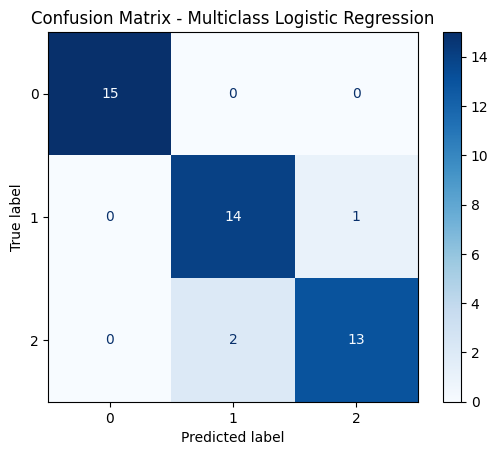

첫 5개 샘플의 클래스별 확률:
 [[1.89009595e-06 3.23277219e-02 9.67670388e-01]
 [4.52959877e-03 7.63798443e-01 2.31671958e-01]
 [9.23750236e-04 5.05594140e-01 4.93482109e-01]
 [5.07028245e-03 6.61724524e-01 3.33205194e-01]
 [1.69317691e-03 4.09580765e-01 5.88726058e-01]]


In [19]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# 데이터 로드
X, y = load_iris(return_X_y=True)

# 학습/테스트 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 다중 클래스 로지스틱 회귀 (softmax)
model = LogisticRegression(multi_class="multinomial", solver="lbfgs", max_iter=200)
model.fit(X_train, y_train)

# 예측
y_pred = model.predict(X_test)

# 정확도 평가
print("Accuracy:", accuracy_score(y_test, y_pred))

# 혼동 행렬 시각화
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Multiclass Logistic Regression")
plt.show()

# 클래스별 확률 예측 (예시: 첫 5개 샘플)
probs = model.predict_proba(X_test[:5])
print("첫 5개 샘플의 클래스별 확률:\n", probs)


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44867 (\N{HANGUL SYLLABLE GGOC}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51086 (\N{HANGUL SYLLABLE IP}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54253 (\N{HANGUL SYLLABLE POG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/loc

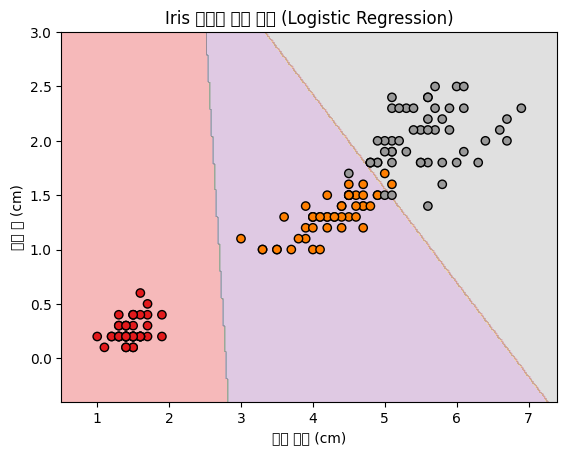

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression

# 1. 데이터 불러오기 (꽃잎 길이, 꽃잎 폭만 사용해서 2D 시각화)
iris = load_iris()
X = iris.data[:, 2:4]  # 꽃잎 길이와 폭
y = iris.target

# 2. 모델 학습
model = LogisticRegression(max_iter=200)
model.fit(X, y)

# 3. 분류 경계선 그리기
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 4. 시각화
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set1)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k', cmap=plt.cm.Set1)
plt.xlabel("flower lengnth (cm)")
plt.ylabel("flower depth (cm)")
plt.title("Iris 데이터 분류 결과 (Logistic Regression)")
plt.show()



꽃잎 길이(cm)를 입력하세요: 5
꽃잎 폭(cm)를 입력하세요: 2

👉 예측 결과: virginica


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44867 (\N{HANGUL SYLLABLE GGOC}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51086 (\N{HANGUL SYLLABLE IP}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54253 (\N{HANGUL SYLLABLE POG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47448 (\N{HANGUL SYLLABLE RYU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/

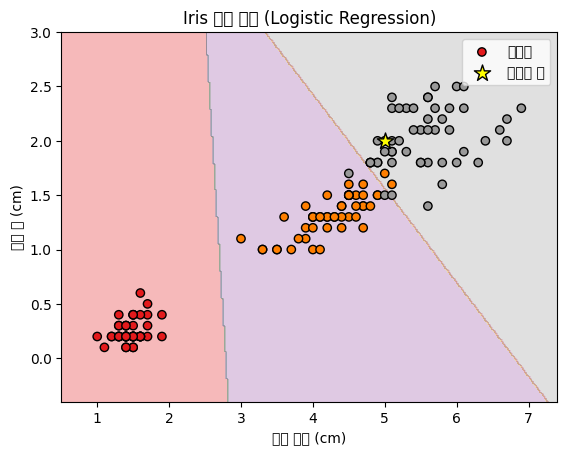

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression

# 1. 데이터 불러오기 (꽃잎 길이, 꽃잎 폭만 사용)
iris = load_iris()
X = iris.data[:, 2:4]  # 꽃잎 길이와 폭
y = iris.target
target_names = iris.target_names

# 2. 모델 학습
model = LogisticRegression(max_iter=200)
model.fit(X, y)

# 3. 분류 경계선 준비
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 4. 사용자 입력 (꽃잎 길이, 폭)
petal_length = float(input("꽃잎 길이(cm)를 입력하세요: "))
petal_width = float(input("꽃잎 폭(cm)를 입력하세요: "))

# 5. 예측
new_point = np.array([[petal_length, petal_width]])
prediction = model.predict(new_point)[0]
print(f"\n👉 예측 결과: {target_names[prediction]}")

# 6. 시각화
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set1)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k", cmap=plt.cm.Set1, label="데이터")
plt.scatter(petal_length, petal_width, c="yellow", edgecolor="black", s=150, marker="*", label="입력한 꽃")
plt.xlabel("꽃잎 길이 (cm)")
plt.ylabel("꽃잎 폭 (cm)")
plt.title("Iris 분류 결과 (Logistic Regression)")
plt.legend()
plt.show()



In [7]:
import streamlit as st
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression


# 1. 데이터 불러오기
iris = load_iris()
X = iris.data[:, 2:4]  # 꽃잎 길이, 폭
y = iris.target
target_names = iris.target_names

# 2. 모델 학습
model = LogisticRegression(max_iter=200)
model.fit(X, y)

# 3. Streamlit UI
st.title("🌸 Iris 꽃 분류기 (Logistic Regression)")
st.write("꽃잎 길이와 폭을 입력하면 어떤 종인지 예측해줍니다.")

# 입력 슬라이더
petal_length = st.slider("꽃잎 길이 (cm)", float(X[:,0].min()), float(X[:,0].max()), 5.0)
petal_width  = st.slider("꽃잎 폭 (cm)", float(X[:,1].min()), float(X[:,1].max()), 1.5)

# 예측
new_point = np.array([[petal_length, petal_width]])
prediction = model.predict(new_point)[0]
st.subheader(f"👉 예측 결과: **{target_names[prediction]}**")

# 4. 그래프 시각화
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

fig, ax = plt.subplots()
ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set1)
ax.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k", cmap=plt.cm.Set1, label="데이터")
ax.scatter(petal_length, petal_width, c="yellow", edgecolor="black", s=150, marker="*", label="입력한 꽃")
ax.set_xlabel("꽃잎 길이 (cm)")
ax.set_ylabel("꽃잎 폭 (cm)")
ax.set_title("Iris 분류 결과")
ax.legend()

st.pyplot(fig)


ModuleNotFoundError: No module named 'streamlit'

In [10]:
%pip install streamlit

In [12]:
import streamlit as st
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression


# 1. 데이터 불러오기
iris = load_iris()
X = iris.data[:, 2:4]  # 꽃잎 길이, 폭
y = iris.target
target_names = iris.target_names

# 2. 모델 학습
model = LogisticRegression(max_iter=200)
model.fit(X, y)

# 3. Streamlit UI
st.title("🌸 Iris 꽃 분류기 (Logistic Regression)")
st.write("꽃잎 길이와 폭을 입력하면 어떤 종인지 예측해줍니다.")

# 입력 슬라이더
petal_length = st.slider("꽃잎 길이 (cm)", float(X[:,0].min()), float(X[:,0].max()), 5.0)
petal_width  = st.slider("꽃잎 폭 (cm)", float(X[:,1].min()), float(X[:,1].max()), 1.5)

# 예측
new_point = np.array([[petal_length, petal_width]])
prediction = model.predict(new_point)[0]
st.subheader(f"👉 예측 결과: **{target_names[prediction]}**")

# 4. 그래프 시각화
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

fig, ax = plt.subplots()
ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set1)
ax.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k", cmap=plt.cm.Set1, label="데이터")
ax.scatter(petal_length, petal_width, c="yellow", edgecolor="black", s=150, marker="*", label="입력한 꽃")
ax.set_xlabel("꽃잎 길이 (cm)")
ax.set_ylabel("꽃잎 폭 (cm)")
ax.set_title("Iris 분류 결과")
ax.legend()

st.pyplot(fig)

2025-09-15 06:37:41.637 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-09-15 06:37:41.639 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-09-15 06:37:41.639 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-09-15 06:37:41.654 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-09-15 06:37:41.656 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-09-15 06:37:41.660 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-09-15 06:37:41.663 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-09-15 06:37:41.664 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()

In [13]:
# 파일명: iris_gradio.py
import gradio as gr
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression

# 1. 데이터 불러오기
iris = load_iris()
X = iris.data[:, 2:4]  # 꽃잎 길이, 폭만 사용
y = iris.target
target_names = iris.target_names

# 2. 모델 학습
model = LogisticRegression(max_iter=200)
model.fit(X, y)

# 3. 예측 + 시각화 함수
def predict_and_plot(petal_length, petal_width):
    # 예측
    new_point = np.array([[petal_length, petal_width]])
    prediction = model.predict(new_point)[0]
    result = f"👉 예측 결과: **{target_names[prediction]}**"

    # 그래프 준비
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    fig, ax = plt.subplots()
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set1)
    ax.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k", cmap=plt.cm.Set1, label="데이터")
    ax.scatter(petal_length, petal_width, c="yellow", edgecolor="black", s=150, marker="*", label="입력한 꽃")
    ax.set_xlabel("꽃잎 길이 (cm)")
    ax.set_ylabel("꽃잎 폭 (cm)")
    ax.set_title("Iris 분류 결과 (Logistic Regression)")
    ax.legend()

    return result, fig

# 4. Gradio 인터페이스
interface = gr.Interface(
    fn=predict_and_plot,
    inputs=[
        gr.Slider(minimum=float(X[:,0].min()), maximum=float(X[:,0].max()), value=5.0, label="꽃잎 길이 (cm)"),
        gr.Slider(minimum=float(X[:,1].min()), maximum=float(X[:,1].max()), value=1.5, label="꽃잎 폭 (cm)")
    ],
    outputs=["markdown", "plot"],
    title="🌸 Iris 꽃 분류기",
    description="꽃잎 길이와 폭을 입력하면 꽃의 종류를 예측합니다."
)

interface.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://11fda7920ebd18baf1.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44867 (\N{HANGUL SYLLABLE GGOC}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51086 (\N{HANGUL SYLLABLE IP}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54253 (\N{HANGUL SYLLABLE POG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47448 (\N{HANGUL SYLLABLE RYU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/

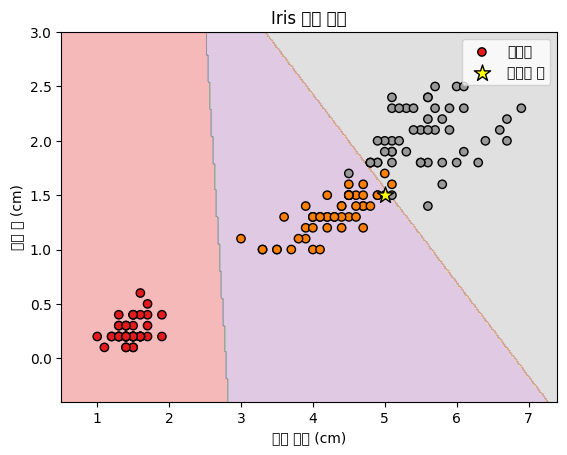

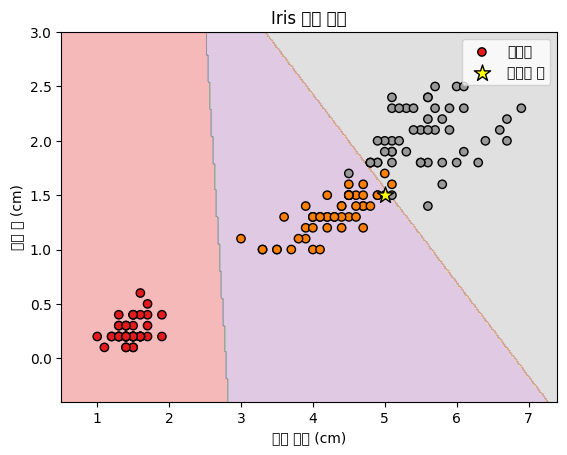

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53364 (\N{HANGUL SYLLABLE KEUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47084 (\N{HANGUL SYLLABLE REO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47553 (\N{HANGUL SYLLABLE RING}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


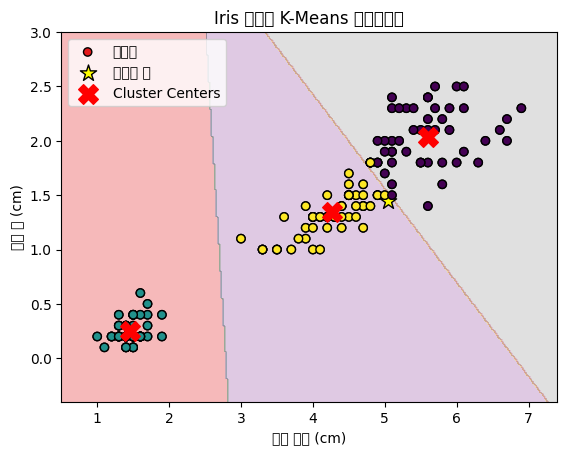

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

# 1. 데이터 불러오기 (꽃잎 길이, 폭)
iris = load_iris()
X = iris.data[:, 2:4]

# 2. KMeans 클러스터링 (3개 그룹으로 나누기)
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X)
labels = kmeans.labels_
centers = kmeans.cluster_centers_

# 3. 시각화
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", marker="o", edgecolor="k")
plt.scatter(centers[:, 0], centers[:, 1], c="red", s=200, marker="X", label="Cluster Centers")
plt.xlabel("꽃잎 길이 (cm)")
plt.ylabel("꽃잎 폭 (cm)")
plt.title("Iris 데이터 K-Means 클러스터링")
plt.legend()
plt.show()


In [17]:
# kmeans_vs_true.py
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, confusion_matrix, accuracy_score

def purity_score(y_true, y_pred):
    """
    Purity = sum(max_j(n_ij)) / N
    where n_ij is count of samples in cluster i that belong to true class j
    """
    cm = confusion_matrix(y_true, y_pred)
    return np.sum(np.amax(cm, axis=1)) / np.sum(cm)

# 1. 데이터 (꽃잎 길이, 폭만 사용해서 2D로 시각화)
iris = load_iris()
X = iris.data[:, 2:4]
y_true = iris.target
target_names = iris.target_names

# 2. KMeans (3 clusters)
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # Added n_init for KMeans stability
kmeans.fit(X)
y_kmeans = kmeans.labels_
centers = kmeans.cluster_centers_

# 3. 성능 지표
ari = adjusted_rand_score(y_true, y_kmeans)
nmi = normalized_mutual_info_score(y_true, y_kmeans)
purity = purity_score(y_true, y_kmeans)

print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")
print(f"Purity: {purity:.4f}")

# 4. (선택) cluster -> label 매핑(majority voting)로 '정확도' 계산
#    주의: 비지도학습이므로 이 값은 클러스터 라벨을 임의로 재매핑한 후의 값 (참고용)
def map_cluster_labels(y_true, y_pred, k):
    cm = confusion_matrix(y_pred, y_true)  # rows: cluster, cols: true label
    mapping = {}
    for cluster_id in range(k):
        # 해당 cluster에서 가장 많은 true-label을 할당
        true_label_for_cluster = np.argmax(cm[cluster_id])
        mapping[cluster_id] = true_label_for_cluster
    # 재매핑
    y_mapped = np.vectorize(mapping.get)(y_pred)
    return y_mapped, mapping

y_mapped, mapping = map_cluster_labels(y_true, y_kmeans, k)
accuracy_after_mapping = accuracy_score(y_true, y_mapped) # Corrected variable name and calculation
print(f"Accuracy after mapping: {accuracy_after_mapping:.4f}") # Print the accuracy

Adjusted Rand Index (ARI): 0.8857
Normalized Mutual Information (NMI): 0.8642
Purity: 0.9600
Accuracy after mapping: 0.9600


Adjusted Rand Index (ARI): 0.8857
Normalized Mutual Information (NMI): 0.8642
Purity: 0.9600
Accuracy after majority-map (informal): 0.9600
Cluster -> mapped true-label: {0: np.int64(2), 1: np.int64(0), 2: np.int64(1)}


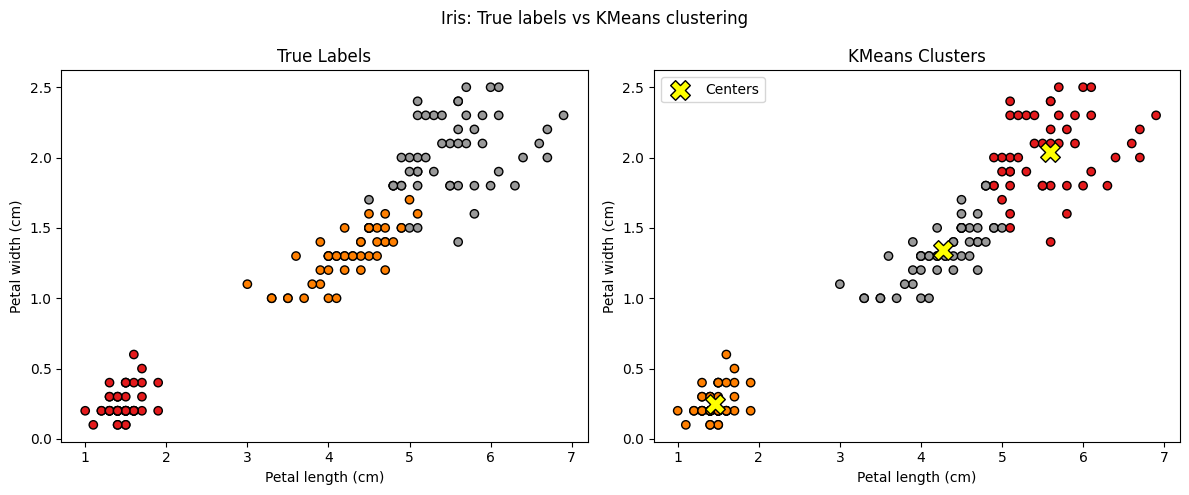

In [18]:
# kmeans_vs_true.py
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, confusion_matrix

def purity_score(y_true, y_pred):
    """
    Purity = sum(max_j(n_ij)) / N
    where n_ij is count of samples in cluster i that belong to true class j
    """
    cm = confusion_matrix(y_true, y_pred)
    return np.sum(np.amax(cm, axis=1)) / np.sum(cm)

# 1. 데이터 (꽃잎 길이, 폭만 사용해서 2D로 시각화)
iris = load_iris()
X = iris.data[:, 2:4]
y_true = iris.target
target_names = iris.target_names

# 2. KMeans (3 clusters)
k = 3
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(X)
y_kmeans = kmeans.labels_
centers = kmeans.cluster_centers_

# 3. 성능 지표
ari = adjusted_rand_score(y_true, y_kmeans)
nmi = normalized_mutual_info_score(y_true, y_kmeans)
purity = purity_score(y_true, y_kmeans)

print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")
print(f"Purity: {purity:.4f}")

# 4. (선택) cluster -> label 매핑(majority voting)로 '정확도' 계산
#    주의: 비지도학습이므로 이 값은 클러스터 라벨을 임의로 재매핑한 후의 값 (참고용)
def map_cluster_labels(y_true, y_pred, k):
    cm = confusion_matrix(y_pred, y_true)  # rows: cluster, cols: true label
    mapping = {}
    for cluster_id in range(k):
        # 해당 cluster에서 가장 많은 true-label을 할당
        true_label_for_cluster = np.argmax(cm[cluster_id])
        mapping[cluster_id] = true_label_for_cluster
    # 재매핑
    y_mapped = np.vectorize(mapping.get)(y_pred)
    return y_mapped, mapping

y_mapped, mapping = map_cluster_labels(y_true, y_kmeans, k)
accuracy_after_mapping = np.mean(y_mapped == y_true)
print(f"Accuracy after majority-map (informal): {accuracy_after_mapping:.4f}")
print("Cluster -> mapped true-label:", mapping)

# 5. 시각화: 좌측=실제 라벨, 우측=클러스터 라벨 (및 클러스터 센터)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 실제 라벨
axes[0].scatter(X[:, 0], X[:, 1], c=y_true, edgecolor='k', cmap=plt.cm.Set1)
axes[0].set_title("True Labels")
axes[0].set_xlabel("Petal length (cm)")
axes[0].set_ylabel("Petal width (cm)")

# 클러스터 라벨
axes[1].scatter(X[:, 0], X[:, 1], c=y_kmeans, edgecolor='k', cmap=plt.cm.Set1)
axes[1].scatter(centers[:, 0], centers[:, 1], c='yellow', edgecolor='black',
                s=200, marker='X', label='Centers')
axes[1].set_title("KMeans Clusters")
axes[1].set_xlabel("Petal length (cm)")
axes[1].set_ylabel("Petal width (cm)")
axes[1].legend()

plt.suptitle("Iris: True labels vs KMeans clustering")
plt.tight_layout()
plt.show()
